In [1]:
#!source /n/holylfs05/LABS/arguelles_delgado_lab/Everyone/jbook/i3/build/env-shell.sh

In [2]:
from I3Tray import I3Tray
from icecube import icetray, dataio, dataclasses, simclasses
from icecube.LeptonInjector import weight_hnl_generation, load_generation_weighting_files, weight_hnl_lifetime_framewise
from icecube.LeptonInjector.oscnext_frame_objects_weighting import create_weight_dict
from icecube.LeptonInjector import hnl_weighting
from icecube.LeptonInjector.oscnext_tools_misc import UpdateFrameObject
import LeptonWeighter as LW

from icecube import icetray, dataio, dataclasses, LeptonInjector
from icecube import tableio, hdfwriter
from I3Tray import I3Units

from icecube.LeptonInjector import hdf5_to_feather
from collections import OrderedDict

try: from tqdm import tqdm
except: tqdm = lambda x: x
    
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import os
import glob as glob

/cvmfs/icecube.opensciencegrid.org/py3-v4.1.1/RHEL_8_x86_64/lib/python3.7/site-packages/ipykernel_launcher.py:1: UserWarning: Using `import I3Tray` or `from I3Tray import *` is now considered depricated. Please switch to using `from icecube.icetray import I3Tray`
  """Entry point for launching an IPython kernel.
/cvmfs/icecube.opensciencegrid.org/py3-v4.1.1/RHEL_8_x86_64/lib/python3.7/importlib/_bootstrap.py:219: RuntimeWarning: to-Python converter for std::vector<char, std::allocator<char> > already registered; second conversion method ignored.
  return f(*args, **kwds)
/cvmfs/icecube.opensciencegrid.org/py3-v4.1.1/RHEL_8_x86_64/lib/python3.7/importlib/_bootstrap.py:219: RuntimeWarning: to-Python converter for std::vector<std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> >, std::allocator<std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> > > > already registered; second conversion method ignored.
  return f(*args, **kwds)
/cvmfs/

In [3]:
import seaborn as sns

In [4]:
event_dir = "/n/holylfs05/LABS/arguelles_delgado_lab/Lab/IceCube_MC/HNL/reconstructed"
signal_dir = f"{event_dir}/estimator_applied/"

In [9]:
loc_keys = [
    # true HNL variables
    "HNL_true_x",
    "HNL_true_y",
    "HNL_true_z",
    "HNL_true_energy",
    "HNL_true_zenith",
    "HNL_true_azimuth",
    "HNL_true_time",
    # true primary variables
    "true_x",
    "true_y",
    "true_z",
    "true_energy",
    "true_zenith",
    "true_azimuth",
    "true_time",
    # true first (DIS) cascade variables
    "casc0_true_x",
    "casc0_true_y",
    "casc0_true_z",
    "casc0_true_energy",
    "casc0_true_zenith",
    "casc0_true_azimuth",
    "casc0_true_time",
    # true second (HNL decay) cascade variables
    "casc1_true_x",
    "casc1_true_y",
    "casc1_true_z",
    "casc1_true_energy",
    "casc1_true_zenith",
    "casc1_true_azimuth",
    "casc1_true_time",
]

# function to get HNL true variables
def get_reconstruction_info(files, nfiles=None):
    info = {"type":[], "pid score": [], "true primary energy": [], "weight": [], 
            "true decay length": [], "reco decay length": []
           }
    pid_key = "dynedge_hnl_pid_test_pid"
    decay_key = "dynedge_dbang_decay_length_dbang_decay_length" #This is not a typo
    
    if nfiles is None: nfiles = len(files)

    # Loop over the files
    for f in tqdm(files):
        i3file = dataio.I3File(f)
        
        # And loop through frames for this file
        while i3file.more():
            frame = i3file.pop_frame()
            
            if frame.Stop != icetray.I3Frame.DAQ: 
                continue
            mctree = frame["I3MCTree"]
            p_true = mctree.primaries[0]
            pid = str(p_true.type)
            energy= p_true.energy
            try:
                weight = frame["I3MCWeightDict"]["TotalInteractionProbabilityWeight"]
            except:
                weight = frame["I3MCWeightDict"]["ReferenceWeight_1e-03"]
                
            
            event_properties = frame["EventProperties"]
            info["true decay length"].append(event_properties.distance)
            
            frame = i3file.pop_frame()
            if frame.Stop != icetray.I3Frame.Physics: 
                continue
            pid_score = frame[pid_key]
            reco_decay_length = frame[decay_key]
            
            info["type"].append(pid)
            info["pid score"].append(pid_score.value)
            info["reco decay length"].append(reco_decay_length.value)
            info["true primary energy"].append(energy)
            info["weight"].append(weight)
    
    return info

In [10]:
signal_files = glob.glob(f"{signal_dir}/*")
# neutrino_files = glob.glob(f"{background_dir}/*")

In [11]:
print(signal_files)

['/n/holylfs05/LABS/arguelles_delgado_lab/Lab/IceCube_MC/HNL/reconstructed/estimator_applied/190300.i3.zst']


In [12]:
hnl_info = get_reconstruction_info(signal_files)

100%|██████████| 1/1 [00:52<00:00, 52.73s/it]


In [13]:
hnl_info=pd.DataFrame(hnl_info)

In [15]:
mask = hnl_info["weight"]>0
print(len(hnl_info[mask]))
print(len(hnl_info))
hnl_info=hnl_info[mask]

93429
126098


In [16]:
hnl_info.to_csv("hnl_reconstruction_info")

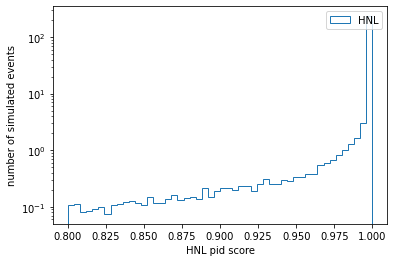

In [22]:
binning = 50

plt.hist(hnl_info["pid score"], histtype="step", label = "HNL", bins = binning, density=True)
plt.yscale("log")
plt.xlabel("HNL pid score")
plt.ylabel("number of simulated events")
plt.legend()

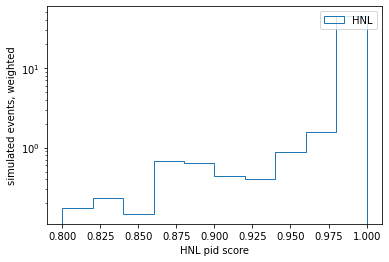

In [21]:
plt.hist(hnl_info["pid score"], histtype="step", label = "HNL", weights = hnl_info["weight"], density=True)
plt.yscale("log")
plt.xlabel("HNL pid score")
plt.ylabel("simulated events, weighted")
plt.legend()

Text(0.5, 1.0, 'Cascade separation, HNL only, high pid set')

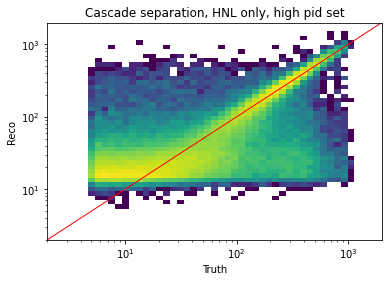

In [25]:
from matplotlib import colors

bins = np.logspace(0.3, 3.3, 50)
plt.hist2d(hnl_info["true decay length"],hnl_info["reco decay length"], bins=bins, norm=colors.LogNorm())
# Add a line 
plt.plot([-2, 2000], [-2, 2000], color='red', linestyle='-', linewidth=1)

plt.xscale('log')
plt.yscale('log')

plt.xlabel("Truth")
plt.ylabel("Reco")
plt.title("Cascade separation, HNL only, high pid set")


Text(0.5, 1.0, 'Cascade error vs true energy, HNL only, high pid set')

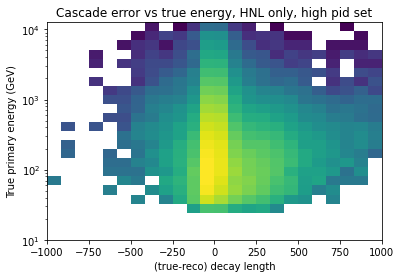

In [36]:
xbins = np.linspace(-1000, 1000, 25)
ybins = np.logspace(1, 4.1, 25 )

plt.hist2d(hnl_info["true decay length"]-hnl_info["reco decay length"], hnl_info["true primary energy"],
           bins=[xbins, ybins], norm=colors.LogNorm(), density=True)
# Add a line 
# plt.plot([-2, 2000], [-2, 2000], color='red', linestyle='-', linewidth=1)

# plt.xscale('log')
plt.yscale('log')

plt.xlabel("(true-reco) decay length")
plt.ylabel("True primary energy (GeV)")
plt.title("Cascade error vs true energy, HNL only, high pid set")